# 03 - Model Comparison
Compare many regression algorithms on the cleaned laptop data.

**Method (same for every model, so the comparison is fair):**
- X = all columns except `Price`, y = `log(Price)`
- Same train/test split: `test_size=0.15`, `random_state=2`
- Categorical columns one-hot encoded (numeric columns scaled for the distance/linear models)
- Hyperparameters tuned with **5-fold cross-validation on the training set only**; the test set is used once, at the end, to report scores

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor,
                              GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
warnings.filterwarnings('ignore', category=UserWarning)   # e.g. unseen rare categories inside CV folds

## Load data, define X / y, split

In [2]:
df = pd.read_csv('laptop_clean.csv')

X = df.drop(columns=['Price'])
y = np.log(df['Price'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=2)
print('Train:', X_train.shape, ' Test:', X_test.shape)

categorical_cols = ['Company', 'TypeName', 'Cpu brand', 'Gpu brand', 'os']
numeric_cols = [c for c in X.columns if c not in categorical_cols]
print('Categorical:', categorical_cols)
print('Numeric:    ', numeric_cols)

Train: (1106, 12)  Test: (196, 12)
Categorical: ['Company', 'TypeName', 'Cpu brand', 'Gpu brand', 'os']
Numeric:     ['Ram', 'Weight', 'Touchscreen', 'Ips', 'ppi', 'SSD', 'HDD']


## Preprocessing
- One-hot encode the categorical columns (`drop='first'` avoids the dummy-variable trap; `handle_unknown='ignore'` copes with rare categories that appear only in a validation/test fold).
- Scale numeric columns for models that depend on distances or coefficient size (Ridge, Lasso, ElasticNet, KNN, SVR). Tree models don't need scaling.

In [3]:
def make_preprocessor(scale_numeric):
    return ColumnTransformer([
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler() if scale_numeric else 'passthrough', numeric_cols),
    ])

def make_pipeline(model, scale_numeric):
    return Pipeline([('preprocess', make_preprocessor(scale_numeric)), ('model', model)])

cv = KFold(n_splits=5, shuffle=True, random_state=2)

## Models and hyperparameter grids
Small grids use `GridSearchCV` (tries every combination); large grids use `RandomizedSearchCV` (tries 40 random combinations).

In [4]:
RS = 2  # random_state for every model that has one

models = {
    'Linear Regression': (LinearRegression(), True, {}),

    'Ridge': (Ridge(), True, {
        'model__alpha': np.logspace(-3, 3, 25)}),

    'Lasso': (Lasso(max_iter=20000), True, {
        'model__alpha': np.logspace(-5, -1, 25)}),

    'ElasticNet': (ElasticNet(max_iter=20000), True, {
        'model__alpha': np.logspace(-5, -1, 15),
        'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}),

    'KNN': (KNeighborsRegressor(), True, {
        'model__n_neighbors': list(range(1, 21)),
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]}),

    'Decision Tree': (DecisionTreeRegressor(random_state=RS), False, {
        'model__max_depth': [None, 4, 6, 8, 10, 12, 15, 20],
        'model__min_samples_split': [2, 5, 10, 20],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__max_features': [None, 0.5, 0.75]}),

    'SVM (SVR)': (SVR(kernel='rbf'), True, {
        'model__C': [1, 3, 10, 30, 100, 300],
        'model__gamma': ['scale', 0.003, 0.01, 0.03, 0.1],
        'model__epsilon': [0.01, 0.05, 0.1]}),

    'Random Forest': (RandomForestRegressor(random_state=RS, n_jobs=1), False, {
        'model__n_estimators': [200, 400, 600],
        'model__max_depth': [None, 10, 15, 20],
        'model__max_features': [0.3, 0.5, 0.75, 1.0],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_samples': [None, 0.5, 0.75]}),

    'Extra Trees': (ExtraTreesRegressor(random_state=RS, n_jobs=1), False, {
        'model__n_estimators': [200, 400, 600],
        'model__max_depth': [None, 10, 15, 20],
        'model__max_features': [0.3, 0.5, 0.75, 1.0],
        'model__min_samples_leaf': [1, 2, 4],
        'model__bootstrap': [False, True]}),

    'AdaBoost': (AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=RS), random_state=RS), False, {
        'model__estimator__max_depth': [3, 5, 8, 12],
        'model__n_estimators': [50, 100, 300, 500],
        'model__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
        'model__loss': ['linear', 'square', 'exponential']}),

    'Gradient Boosting': (GradientBoostingRegressor(random_state=RS), False, {
        'model__n_estimators': [200, 400, 700, 1000],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [2, 3, 4, 5, 6],
        'model__subsample': [0.6, 0.8, 1.0],
        'model__max_features': [0.3, 0.5, 0.75, None],
        'model__min_samples_leaf': [1, 3, 5]}),

    'Hist Gradient Boosting': (HistGradientBoostingRegressor(random_state=RS), False, {
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_iter': [200, 400, 700],
        'model__max_leaf_nodes': [8, 15, 31, 63],
        'model__min_samples_leaf': [5, 10, 20],
        'model__l2_regularization': [0.0, 0.1, 1.0]}),

    'XGBoost': (XGBRegressor(random_state=RS, n_jobs=1, tree_method='hist'), False, {
        'model__n_estimators': [300, 500, 800, 1200],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__max_depth': [3, 4, 5, 6, 8],
        'model__subsample': [0.6, 0.8, 1.0],
        'model__colsample_bytree': [0.4, 0.6, 0.8, 1.0],
        'model__min_child_weight': [1, 3, 5],
        'model__reg_lambda': [0.5, 1, 5]}),
}

print(len(models), 'models to tune')

13 models to tune


## Tune every model (5-fold CV on the training set) and score it on the test set

In [5]:
def grid_size(grid):
    n = 1
    for values in grid.values():
        n *= len(values)
    return n

def evaluate(name, fitted_pipe, cv_r2, params, seconds):
    pred_train = fitted_pipe.predict(X_train)
    pred_test = fitted_pipe.predict(X_test)
    return {
        'Model': name,
        'CV R2 (train folds)': cv_r2,
        'Train R2': r2_score(y_train, pred_train),
        'Test R2': r2_score(y_test, pred_test),
        'Test MAE (log)': mean_absolute_error(y_test, pred_test),
        'Test MAE (price)': mean_absolute_error(np.exp(y_test), np.exp(pred_test)),
        'Time (s)': seconds,
        'Best params': params,
    }

results = []
best_pipes = {}

for name, (model, scale, grid) in models.items():
    start = time.time()
    pipe = make_pipeline(model, scale)

    if not grid:                                   # nothing to tune (plain Linear Regression)
        cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2').mean()
        best = pipe.fit(X_train, y_train)
        params = {}
    else:
        if grid_size(grid) <= 60:
            search = GridSearchCV(pipe, grid, cv=cv, scoring='r2', n_jobs=-1)
        else:
            search = RandomizedSearchCV(pipe, grid, n_iter=40, cv=cv, scoring='r2', n_jobs=-1, random_state=RS)
        search.fit(X_train, y_train)
        best, cv_r2 = search.best_estimator_, search.best_score_
        params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}

    best_pipes[name] = best
    results.append(evaluate(name, best, cv_r2, params, time.time() - start))
    print(f"{name:<24} CV R2 = {cv_r2:.4f} | Test R2 = {results[-1]['Test R2']:.4f} | {time.time() - start:5.1f}s")

Linear Regression        CV R2 = 0.8176 | Test R2 = 0.8073 |   0.1s


Ridge                    CV R2 = 0.8177 | Test R2 = 0.8079 |   3.7s


Lasso                    CV R2 = 0.8176 | Test R2 = 0.8076 |   0.3s


ElasticNet               CV R2 = 0.8176 | Test R2 = 0.8077 |   0.6s


KNN                      CV R2 = 0.8547 | Test R2 = 0.8745 |   0.8s


...

Extra Trees              CV R2 = 0.8687 | Test R2 = 0.8923 |  21.6s


AdaBoost                 CV R2 = 0.8767 | Test R2 = 0.8830 |  16.6s


Gradient Boosting        CV R2 = 0.8912 | Test R2 = 0.9057 |  15.9s


Hist Gradient Boosting   CV R2 = 0.8878 | Test R2 = 0.9082 |  23.9s


XGBoost                  CV R2 = 0.8972 | Test R2 = 0.8958 |   6.2s


## Ensembles (extra models)
Combine the best tuned models. The members are picked by **cross-validation score**, not test score, so the test set stays unseen.
- **Voting**: average of the members' predictions.
- **Stacking**: a Ridge model learns how much to trust each member.

In [6]:
# Top 4 individual models by CV R2
top_names = (pd.DataFrame(results).sort_values('CV R2 (train folds)', ascending=False)['Model'].head(4).tolist())
print('Ensemble members:', top_names)
members = [(n, best_pipes[n]) for n in top_names]

ensembles = {
    'Voting (top 4)': VotingRegressor(members, n_jobs=-1),
    'Stacking (top 4 -> Ridge)': StackingRegressor(members, final_estimator=Ridge(alpha=1.0), cv=cv, n_jobs=-1),
}

for name, ens in ensembles.items():
    start = time.time()
    cv_r2 = cross_val_score(ens, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1).mean()
    ens.fit(X_train, y_train)
    best_pipes[name] = ens
    results.append(evaluate(name, ens, cv_r2, {'members': top_names}, time.time() - start))
    print(f"{name:<26} CV R2 = {cv_r2:.4f} | Test R2 = {results[-1]['Test R2']:.4f} | {time.time() - start:5.1f}s")

Ensemble members: ['XGBoost', 'Gradient Boosting', 'Hist Gradient Boosting', 'Random Forest']


Voting (top 4)             CV R2 = 0.8969 | Test R2 = 0.9098 |   2.9s


Stacking (top 4 -> Ridge)  CV R2 = 0.8978 | Test R2 = 0.9047 |  14.3s


## Comparison table

In [7]:
results_df = (pd.DataFrame(results)
              .sort_values('Test R2', ascending=False)
              .reset_index(drop=True))
results_df.index = results_df.index + 1

summary = results_df.drop(columns=['Best params']).round(4)
summary['Test MAE (price)'] = summary['Test MAE (price)'].round(0)
summary['Time (s)'] = summary['Time (s)'].round(1)
summary

,Model,CV R2 (train folds),Train R2,Test R2,Test MAE (log),Test MAE (price),Time (s)
1,Voting (top 4),0.8969,0.9707,0.9098,0.1416,7934.0,2.7
2,Hist Gradient Boosting,0.8878,0.9669,0.9082,0.1436,8198.0,23.8
3,Gradient Boosting,0.8912,0.9670,0.9057,0.1470,8398.0,15.9
4,Stacking (top 4 -> Ridge),0.8978,0.9715,0.9047,0.1451,8130.0,14.0
5,Random Forest,0.8798,0.9677,0.8987,0.1514,8633.0,16.5
6,XGBoost,0.8972,0.9698,0.8958,0.1498,8306.0,6.2
7,Extra Trees,0.8687,0.9727,0.8923,0.1545,8843.0,21.6
8,AdaBoost,0.8767,0.9590,0.8830,0.1628,9120.0,16.5
9,SVM (SVR),0.8746,0.9155,0.8779,0.1607,9302.0,4.3
10,KNN,0.8547,0.9962,0.8745,0.1555,9044.0,0.7


In [8]:
# Best hyperparameters found for each model
for _, row in results_df.iterrows():
    print(f"{row['Model']}: {row['Best params']}")

Voting (top 4): {'members': ['XGBoost', 'Gradient Boosting', 'Hist Gradient Boosting', 'Random Forest']}
Hist Gradient Boosting: {'min_samples_leaf': 10, 'max_leaf_nodes': 8, 'max_iter': 700, 'learning_rate': 0.1, 'l2_regularization': 1.0}
Gradient Boosting: {'subsample': 0.6, 'n_estimators': 700, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 5, 'learning_rate': 0.05}
Stacking (top 4 -> Ridge): {'members': ['XGBoost', 'Gradient Boosting', 'Hist Gradient Boosting', 'Random Forest']}
Random Forest: {'n_estimators': 600, 'min_samples_leaf': 1, 'max_samples': 0.75, 'max_features': 0.3, 'max_depth': 15}
XGBoost: {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.4}
Extra Trees: {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15, 'bootstrap': True}
AdaBoost: {'n_estimators': 300, 'loss': 'exponential', 'learning_rate': 0.5, 'estimator__max_depth': 8}
SVM (SVR): {

## Visual comparison

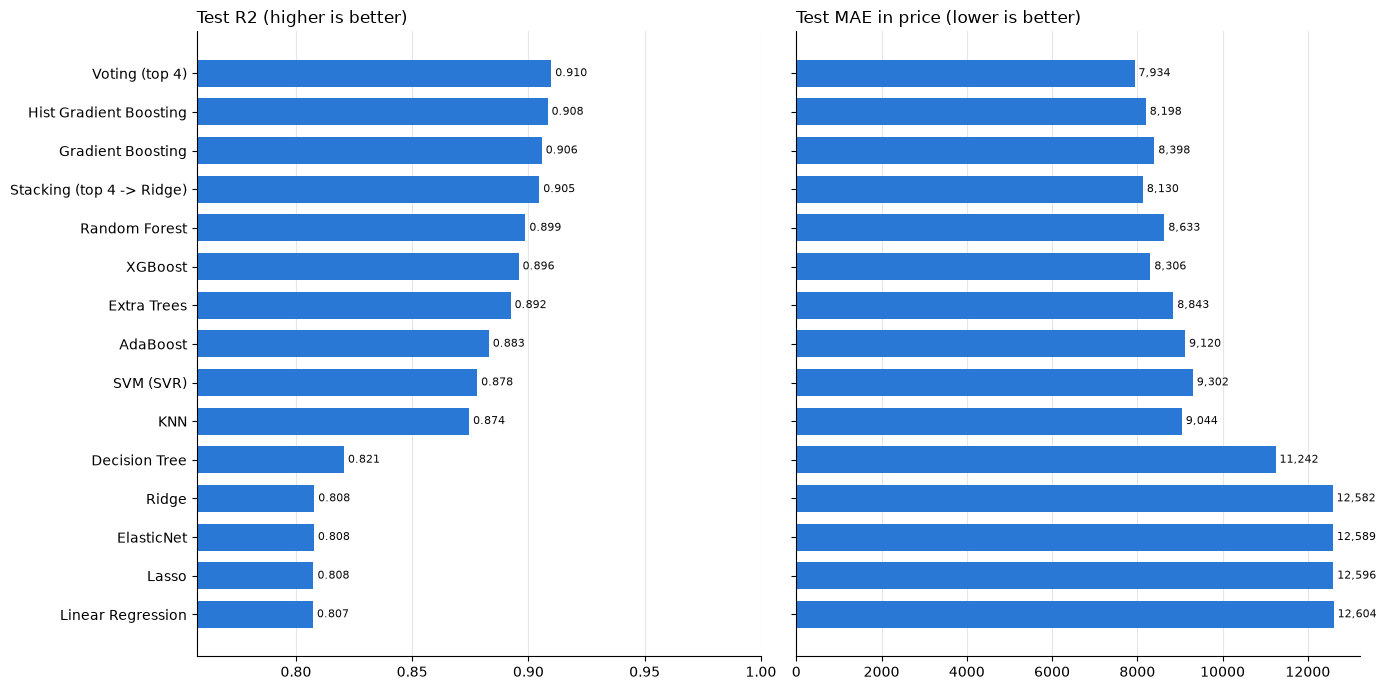

In [9]:
plot_df = results_df.sort_values('Test R2')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

axes[0].barh(plot_df['Model'], plot_df['Test R2'], color='#2a78d6', height=0.7)
axes[0].set_xlim(plot_df['Test R2'].min() - 0.05, 1.0)
axes[0].set_title('Test R2 (higher is better)', loc='left')
for y_pos, v in enumerate(plot_df['Test R2']):
    axes[0].text(v, y_pos, f' {v:.3f}', va='center', fontsize=8, color='#0b0b0b')

axes[1].barh(plot_df['Model'], plot_df['Test MAE (price)'], color='#2a78d6', height=0.7)
axes[1].set_title('Test MAE in price (lower is better)', loc='left')
for y_pos, v in enumerate(plot_df['Test MAE (price)']):
    axes[1].text(v, y_pos, f' {v:,.0f}', va='center', fontsize=8, color='#0b0b0b')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color='#e6e6e3', linewidth=0.8)
    ax.set_axisbelow(True)

plt.tight_layout()
fig.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## Best model

In [10]:
# Pick the winner by CV R2 (chosen without looking at the test set); report its test scores
best_row = results_df.sort_values('CV R2 (train folds)', ascending=False).iloc[0]
print('Best model by CV R2:', best_row['Model'])
print(f"  CV R2          : {best_row['CV R2 (train folds)']:.4f}")
print(f"  Test R2        : {best_row['Test R2']:.4f}")
print(f"  Test MAE (log) : {best_row['Test MAE (log)']:.4f}")
print(f"  Test MAE (price): {best_row['Test MAE (price)']:,.0f}")

Best model by CV R2: Stacking (top 4 -> Ridge)
  CV R2          : 0.8978
  Test R2        : 0.9047
  Test MAE (log) : 0.1451
  Test MAE (price): 8,130
